In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [ ]:
files = os.listdir(r'/content/drive/MyDrive/uber')

In [ ]:
files.remove('uber-raw-data-janjune-15.csv')

In [ ]:
# drive/MyDrive/datasets/uber

path = r'/content/drive/MyDrive/uber'

final = pd.DataFrame()

for file in files:
  df = pd.read_csv(path + '/' + file, encoding = 'utf-8')
  final = pd.concat([df, final])

In [ ]:
final.shape

(4534327, 4)

In [ ]:
final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


In [ ]:
df = final.copy()
df.head()

,Date/Time,Lat,Lon,Base
0,6/1/2014 0:00:00,40.7293,-73.9920,B02512
1,6/1/2014 0:01:00,40.7131,-74.0097,B02512
2,6/1/2014 0:04:00,40.3461,-74.6610,B02512
3,6/1/2014 0:04:00,40.7555,-73.9833,B02512
4,6/1/2014 0:07:00,40.6880,-74.1831,B02512


In [ ]:
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format = '%m/%d/%Y %H:%M:%S')

In [ ]:
df.dtypes

Date/Time    datetime64[ns]
Lat                 float64
Lon                 float64
Base                 object
dtype: object

In [ ]:
df['month'] = df['Date/Time'].dt.month
df['day'] = df['Date/Time'].dt.day
df['weekday'] = df['Date/Time'].dt.day_name()
df['hour'] = df['Date/Time'].dt.hour
df['minute'] = df['Date/Time'].dt.minute

In [ ]:
df.dtypes

Date/Time    datetime64[ns]
Lat                 float64
Lon                 float64
Base                 object
month                 int32
day                   int32
weekday              object
hour                  int32
minute                int32
dtype: object

In [ ]:
df.head()

,Date/Time,Lat,Lon,Base,month,day,weekday,hour,minute
0,2014-06-01 00:00:00,40.7293,-73.9920,B02512,6,1,Sunday,0,0
1,2014-06-01 00:01:00,40.7131,-74.0097,B02512,6,1,Sunday,0,1
2,2014-06-01 00:04:00,40.3461,-74.6610,B02512,6,1,Sunday,0,4
3,2014-06-01 00:04:00,40.7555,-73.9833,B02512,6,1,Sunday,0,4
4,2014-06-01 00:07:00,40.6880,-74.1831,B02512,6,1,Sunday,0,7


In [ ]:
df['Base'].unique()

array(['B02512', 'B02598', 'B02617', 'B02682', 'B02764'], dtype=object)

In [ ]:
df['day'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31],
      dtype=int32)

In [ ]:
df['weekday'].unique()

array(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday',
       'Saturday'], dtype=object)

## Analisa 1: Pada hari apa traffic Uber paling banyak dan paling sedikit di tahun 2014?


In [ ]:
import plotly.express as px

In [ ]:
px.bar(x = df['weekday'].value_counts().index,
       y = df['weekday'].value_counts().values
       )

## Analisa 2: Pada jam berapa traffic Uber tertinggi dan terendah?


(array([216928., 103517., 227152., 543565., 324851., 366329., 819491.,
        660869., 579117., 692508.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ]),
 <BarContainer object of 10 artists>)

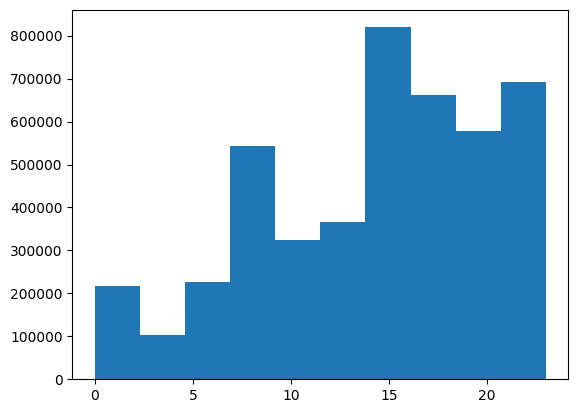

In [ ]:
plt.hist(df['hour'])

## Analisa 3: Setiap bulannya, pada jam berapa traffic Uber tertinggi dan terendahnya?


In [ ]:
for i, month in enumerate(df['month'].unique()):
  print (month)

6
5
9
7
8
4


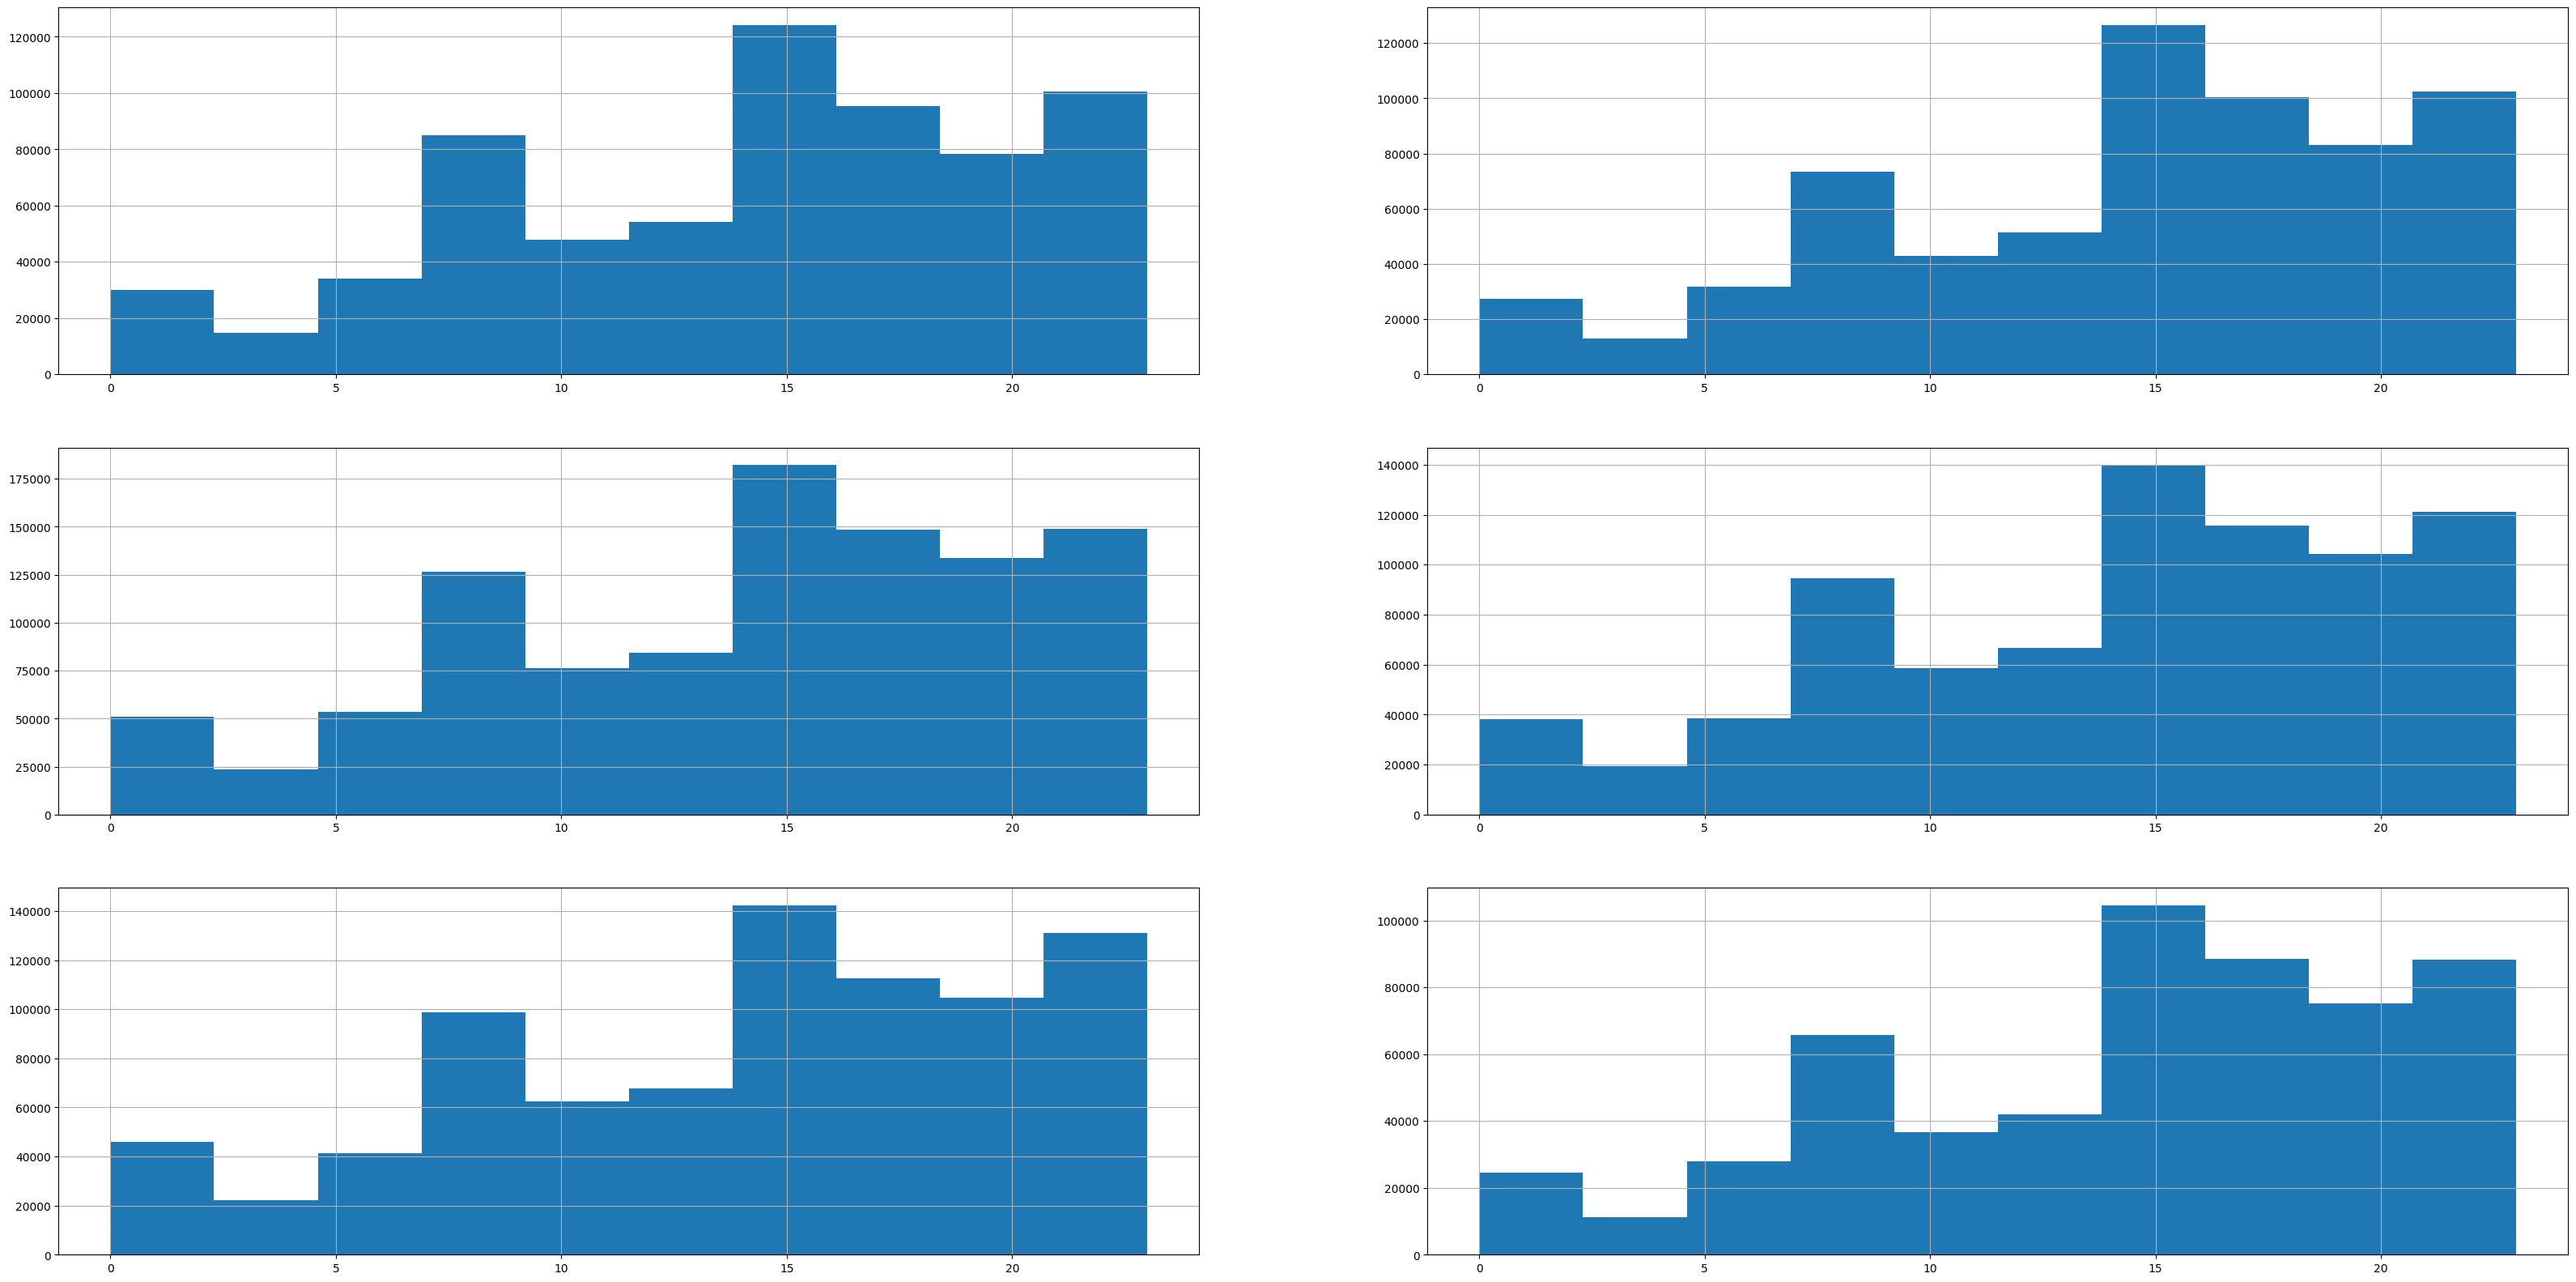

In [ ]:
plt.figure(figsize = (40, 20))
for i, month in enumerate(df['month'].unique()):
  plt.subplot(3, 2, i + 1)
  df[df['month'] == month]['hour'].hist()

## Analisa 4: Pada jam berapa setiap bulannya, traffic Uber tertinggi dan terendah?


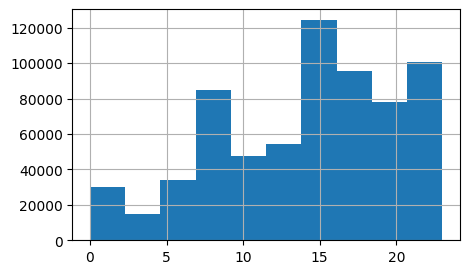

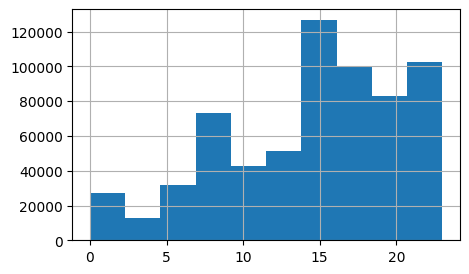

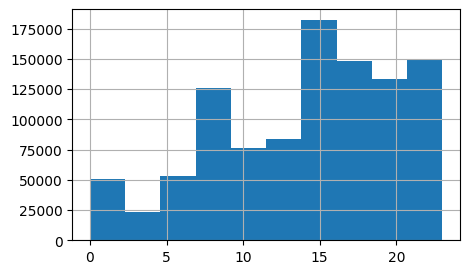

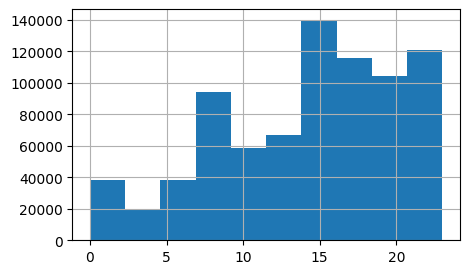

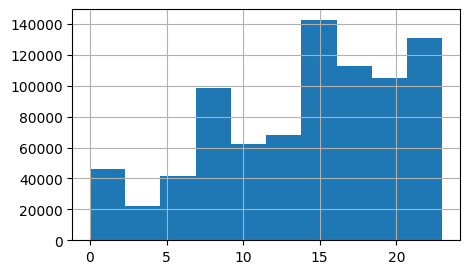

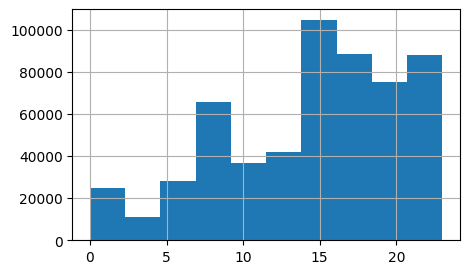

In [ ]:
for i in df['month'].unique():
  plt.figure(figsize = (5, 3))
  df[df['month'] == i]['hour'].hist()

## Analisa 5: Pada bulan apa total traffic Uber yang paling lama?


In [ ]:
!pip install chart_studio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 964.0 kB/s eta 0:00:00


In [ ]:
import chart_studio.plotly as py
import plotly.graph_objs as go
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

## Analisa 6: Total jumlah perjalanan di Uber berdasarkan tanggal dalam satu bulan seama 2014.


Text(0.5, 1.0, 'Jouneys by Month for Each Day')

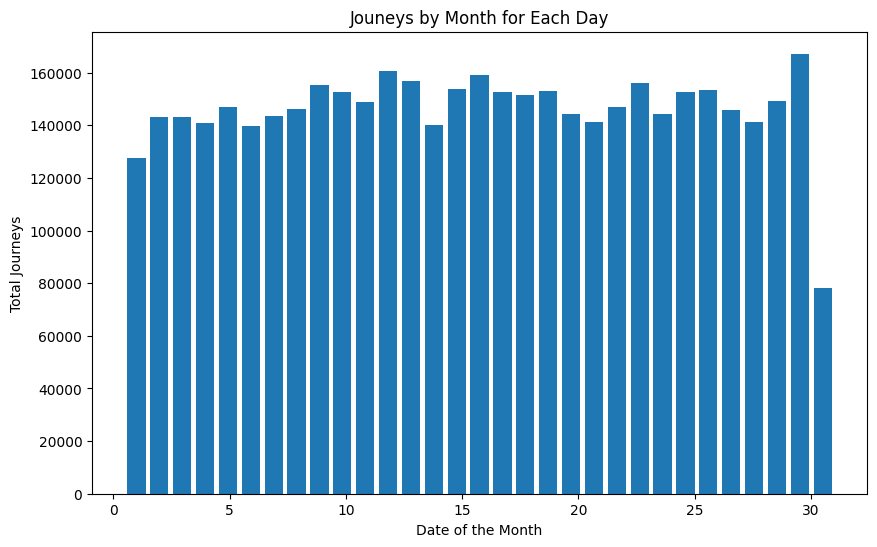

In [ ]:
plt.figure(figsize = (10, 6))
plt.hist(df['day'], bins = 31, rwidth = .8, range = (0.5, 31))
plt.xlabel('Date of the Month')
plt.ylabel('Total Journeys')
plt.title('Jouneys by Month for Each Day')

## Analisa 7: Jumlah perjalanan Uber berdasarkan tangga dan bulannya.


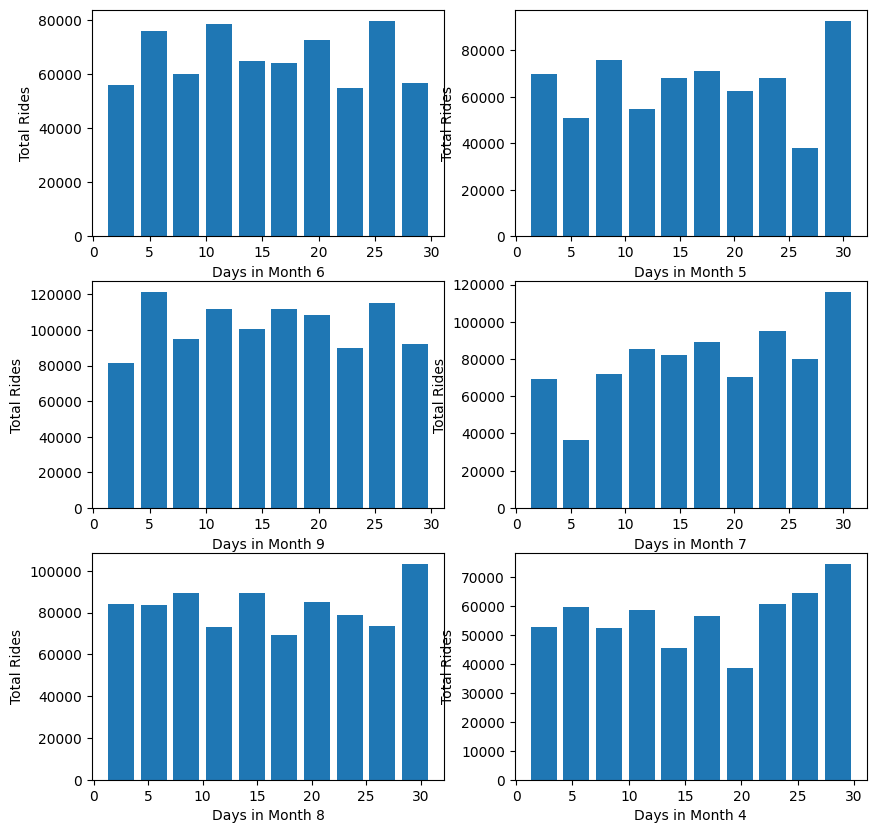

In [ ]:
plt.figure(figsize = (10, 10))
for i, month in enumerate(df['month'].unique(), 1):
  plt.subplot(3, 2, i)
  df_out = df[df['month'] == month]
  plt.hist(df_out['day'], rwidth = .8)
  plt.xlabel('Days in Month %i' %month)
  plt.ylabel('Total Rides')

## Analisa 8: Kepadatan traffic Uber berdasarkan jam dan latitude-nya.


<Axes: xlabel='hour', ylabel='Lat'>

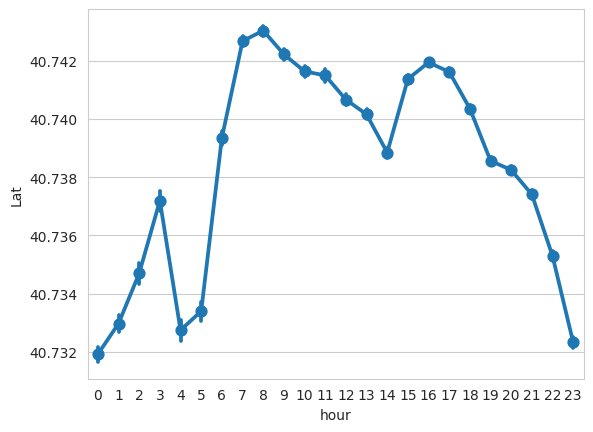

In [ ]:
sns.set_style(style = 'whitegrid')
sns.pointplot(x = 'hour', y = 'Lat', data = df)

Text(0.5, 1.0, 'Hour vs Weekday vs Latitude of Passengers')

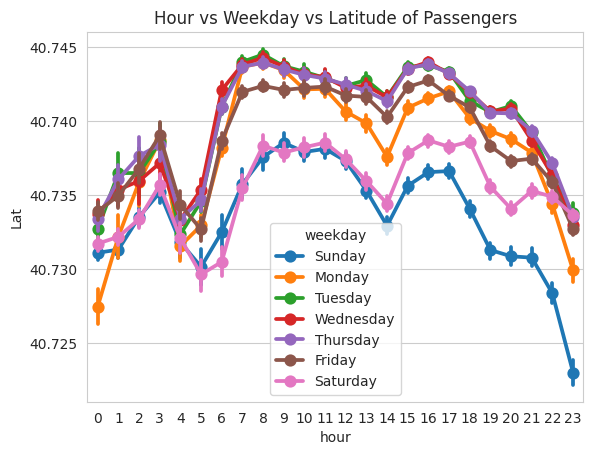

In [ ]:
ax = sns.pointplot(x = 'hour', y = 'Lat', hue = 'weekday', data = df)
ax.set_title('Hour vs Weekday vs Latitude of Passengers')

Text(0.5, 1.0, 'Hour vs Weekday vs Latitude of Passengers')

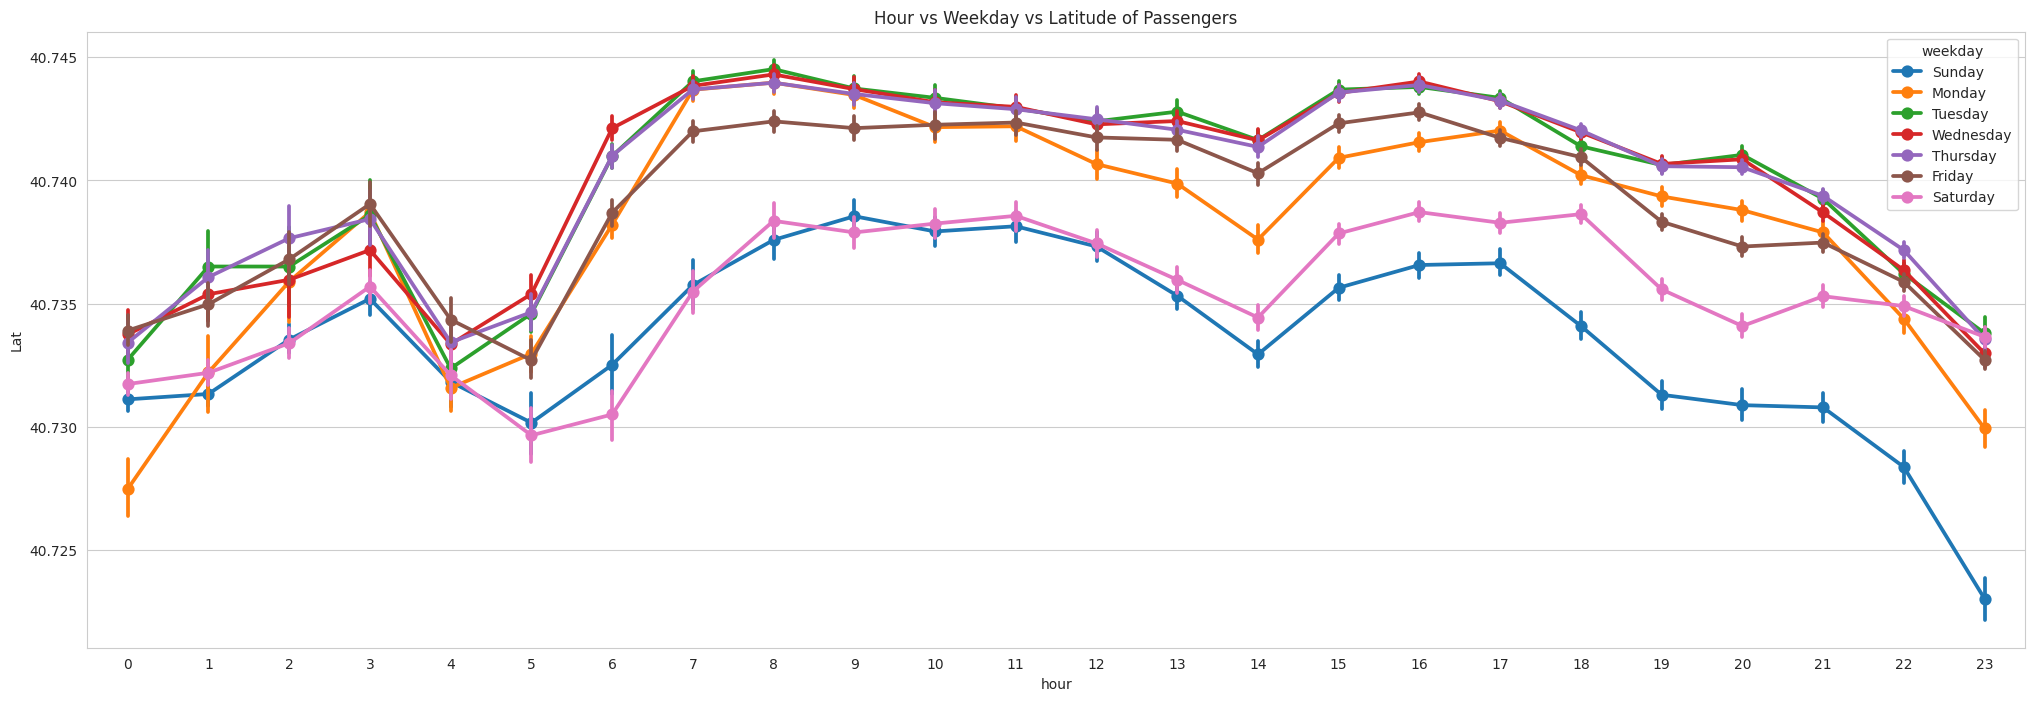

In [ ]:
plt.figure(figsize = (25, 8))
ax = sns.pointplot(x = 'hour', y = 'Lat', hue = 'weekday', data = df)
ax.set_title('Hour vs Weekday vs Latitude of Passengers')

## Analisa 9: Base mana yang paling banyak digunakan dalam perjalanan Uber?


In [ ]:
# Soal No. 9.1

In [ ]:
df['Base'].value_counts()

Base
B02617    1458853
B02598    1393113
B02682    1212789
B02764     263899
B02512     205673
Name: count, dtype: int64

In [ ]:
pt = df.pivot_table(values = 'day', index = 'month', columns = 'Base', aggfunc = 'count')

pt

Base,B02512,B02598,B02617,B02682,B02764
month,,,,,
4,35536,183263,108001,227808,9908
5,36765,260549,122734,222883,9504
6,32509,242975,184460,194926,8974
7,35021,245597,310160,196754,8589
8,31472,220129,355803,173280,48591
9,34370,240600,377695,197138,178333


<Axes: xlabel='month'>

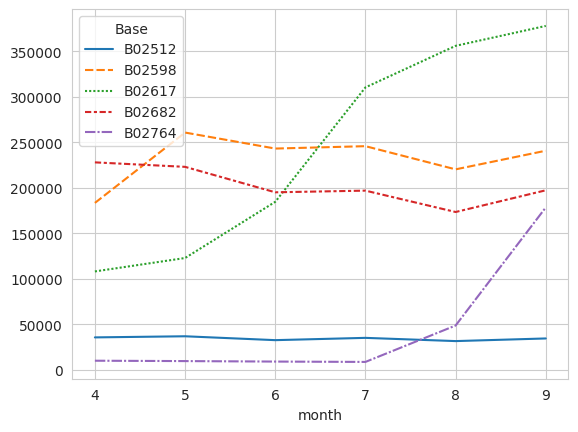

In [ ]:
sns.lineplot(data = pt)

Base yang paling banyak digunakan yakni B02617, dengan total 1458853 kali. Selain itu dapat dilihat dari grafik lineplot, Base B02617 selalu mengalami kenaikan jumlah penggunaan jasa dari bulan ke bulan, dan paling banyak digunakan pada bulan ke-9.


In [ ]:
# Soal No. 9.2

<Axes: xlabel='Base', ylabel='count'>

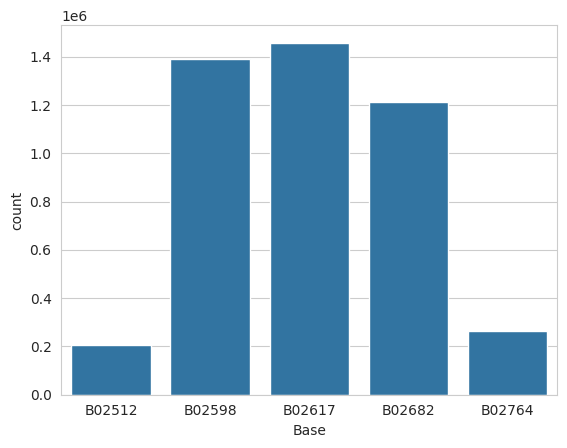

In [ ]:
sns.countplot(x = 'Base', data = df)